# 02 — Feature Extraction & Visualization
Extract features from RGB and Thermal images using the dual-stream backbone.

This notebook:
- Loads pretrained ResNet backbones
- Extracts multi-scale features from both modalities
- Visualizes feature maps at different scales
- Compares RGB vs Thermal feature activations

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

from src.backbone import DualStreamBackbone, ResNetBackbone
from src.utils import create_sample_data, get_device
from src.dataset import MultiModalDataset

%matplotlib inline
device = get_device('auto')
print(f'Using device: {device}')

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## 1. Prepare Sample Data

In [2]:
DATA_DIR = os.path.join('..', 'data', 'sample')
if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    create_sample_data(DATA_DIR, num_samples=10)

dataset = MultiModalDataset(
    root_dir=DATA_DIR,
    annotation_file=os.path.join(DATA_DIR, 'annotations.json'),
    img_size=(640, 640)
)

sample = dataset[0]
rgb_input = sample['rgb'].unsqueeze(0).to(device)
thermal_input = sample['thermal'].unsqueeze(0).to(device)

print(f'RGB input: {rgb_input.shape}')
print(f'Thermal input: {thermal_input.shape}')

RGB input: torch.Size([1, 3, 640, 640])
Thermal input: torch.Size([1, 3, 640, 640])


## 2. Extract Features with Dual-Stream Backbone

In [3]:
# Initialize dual-stream backbone
backbone = DualStreamBackbone(
    model_name='resnet34',
    pretrained=True,
    freeze_stages=0,
    share_weights=False
).to(device)

backbone.eval()

# Extract features
with torch.no_grad():
    rgb_features, thermal_features = backbone(rgb_input, thermal_input)

print('Feature map shapes:')
for i, (rf, tf) in enumerate(zip(rgb_features, thermal_features)):
    print(f'  Level {i+1}: RGB {rf.shape} | Thermal {tf.shape}')

Feature map shapes:
  Level 1: RGB torch.Size([1, 64, 160, 160]) | Thermal torch.Size([1, 64, 160, 160])
  Level 2: RGB torch.Size([1, 128, 80, 80]) | Thermal torch.Size([1, 128, 80, 80])
  Level 3: RGB torch.Size([1, 256, 40, 40]) | Thermal torch.Size([1, 256, 40, 40])
  Level 4: RGB torch.Size([1, 512, 20, 20]) | Thermal torch.Size([1, 512, 20, 20])


## 3. Visualize Multi-Scale Feature Maps

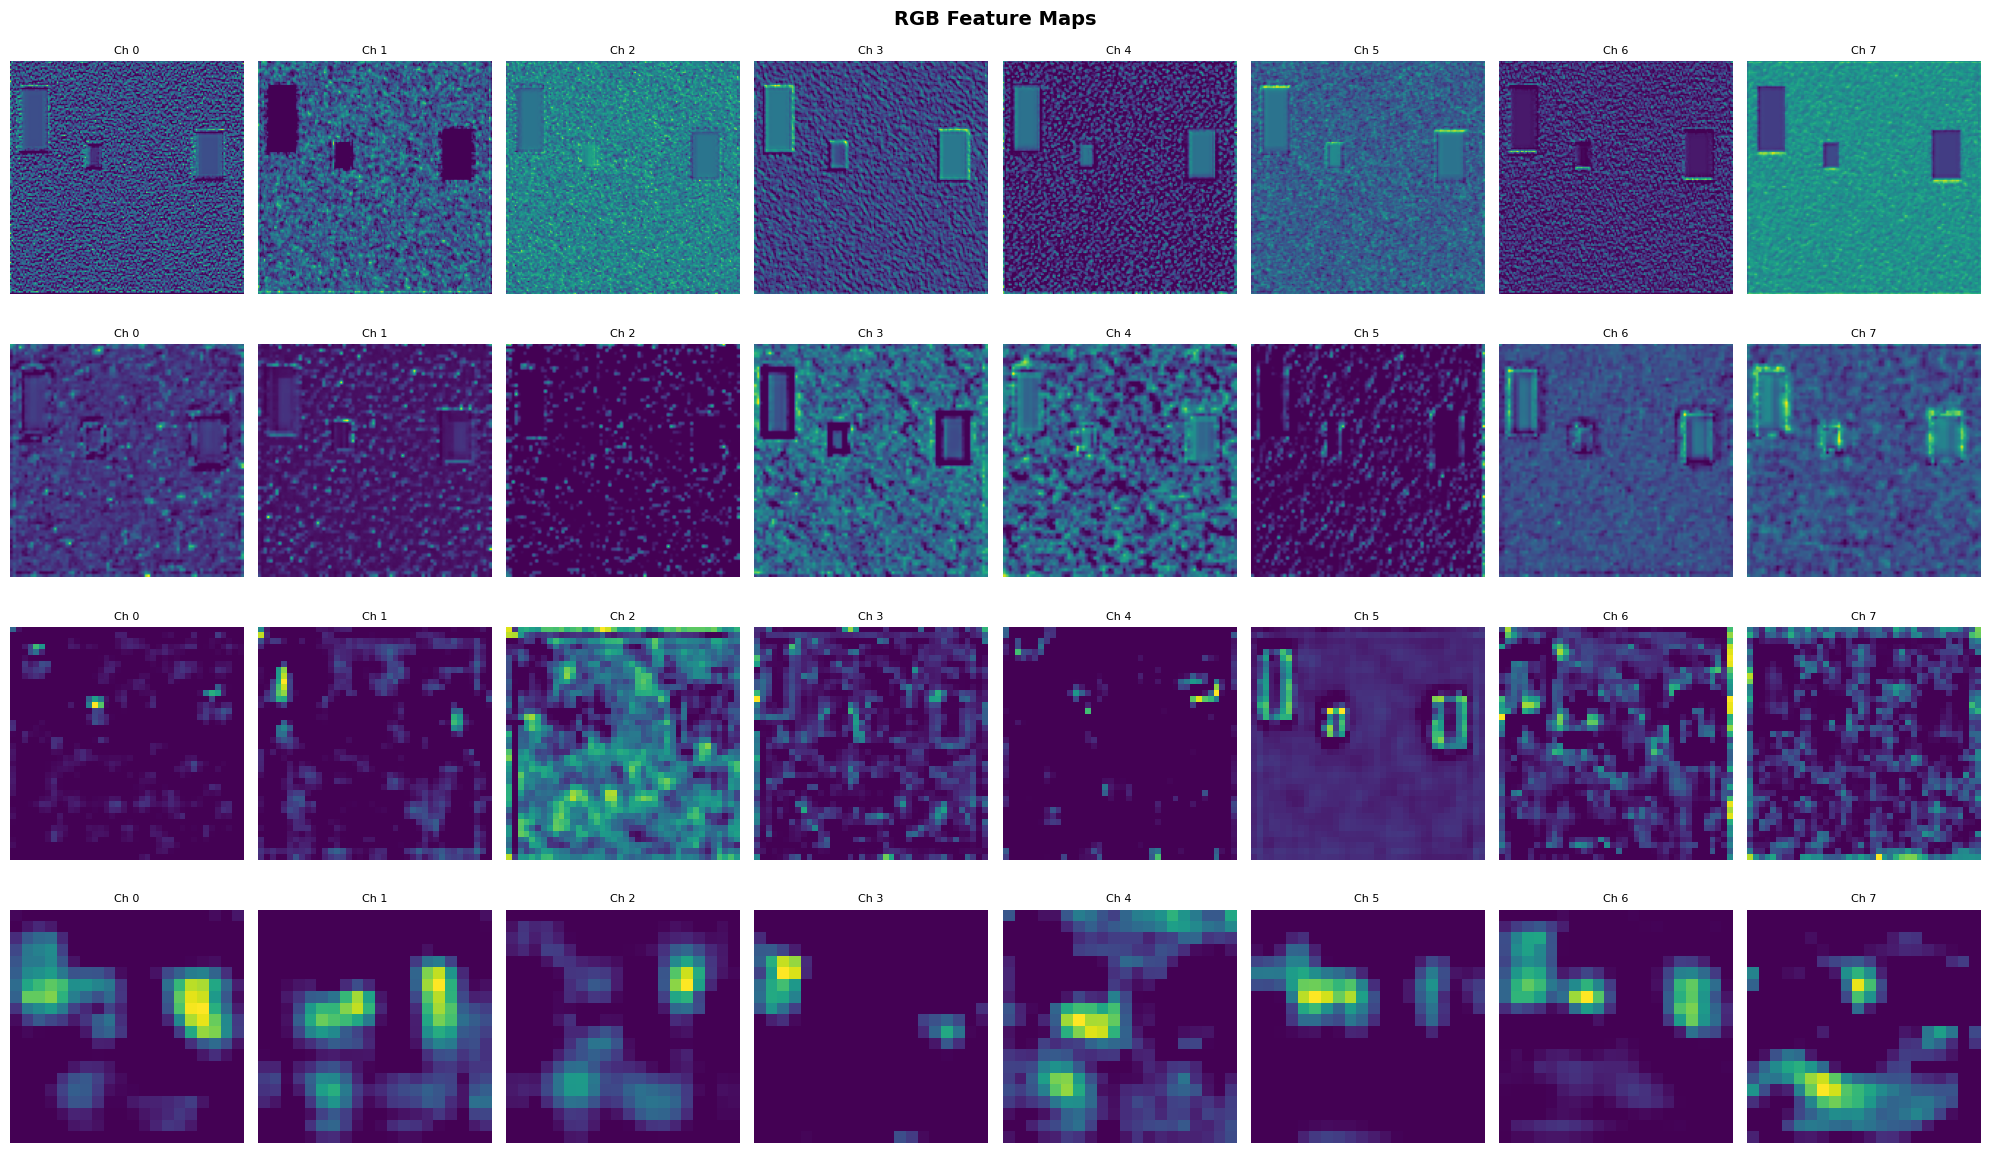

In [4]:
def visualize_feature_maps(features, title_prefix='', num_channels=8):
    """Visualize feature maps from different backbone stages."""
    num_levels = len(features)
    fig, axes = plt.subplots(num_levels, num_channels, figsize=(20, 3*num_levels))
    
    for level_idx, feat in enumerate(features):
        feat_np = feat[0].cpu().numpy()  # (C, H, W)
        
        for ch_idx in range(min(num_channels, feat_np.shape[0])):
            ax = axes[level_idx, ch_idx] if num_levels > 1 else axes[ch_idx]
            ax.imshow(feat_np[ch_idx], cmap='viridis')
            if ch_idx == 0:
                ax.set_ylabel(f'{title_prefix}\nL{level_idx+1}\n{feat_np.shape[1]}x{feat_np.shape[2]}', fontsize=9)
            ax.set_title(f'Ch {ch_idx}', fontsize=8)
            ax.axis('off')
    
    plt.suptitle(f'{title_prefix} Feature Maps', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Visualize RGB features
visualize_feature_maps(rgb_features, 'RGB')

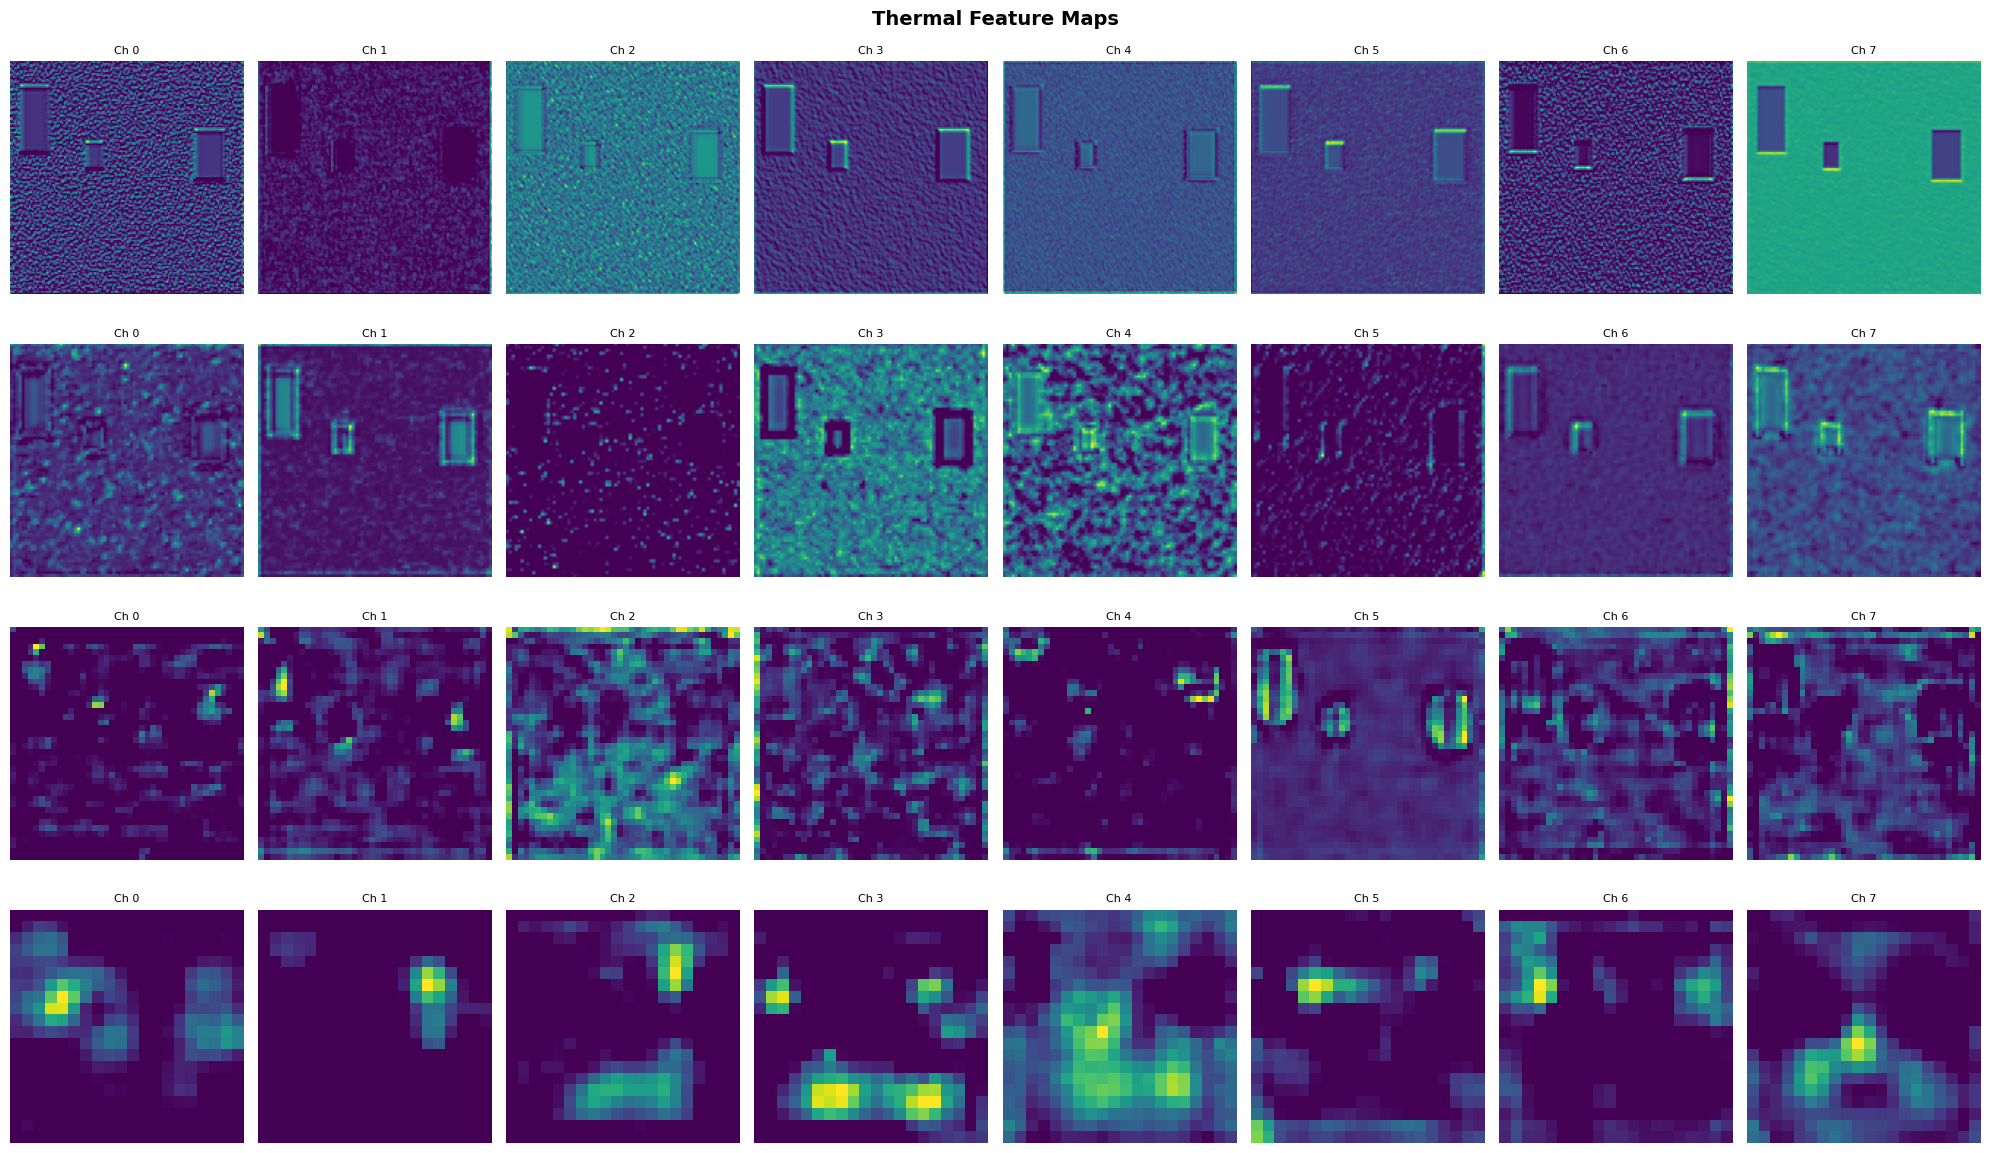

In [5]:
# Visualize Thermal features
visualize_feature_maps(thermal_features, 'Thermal')

## 4. Compare Feature Activation Statistics

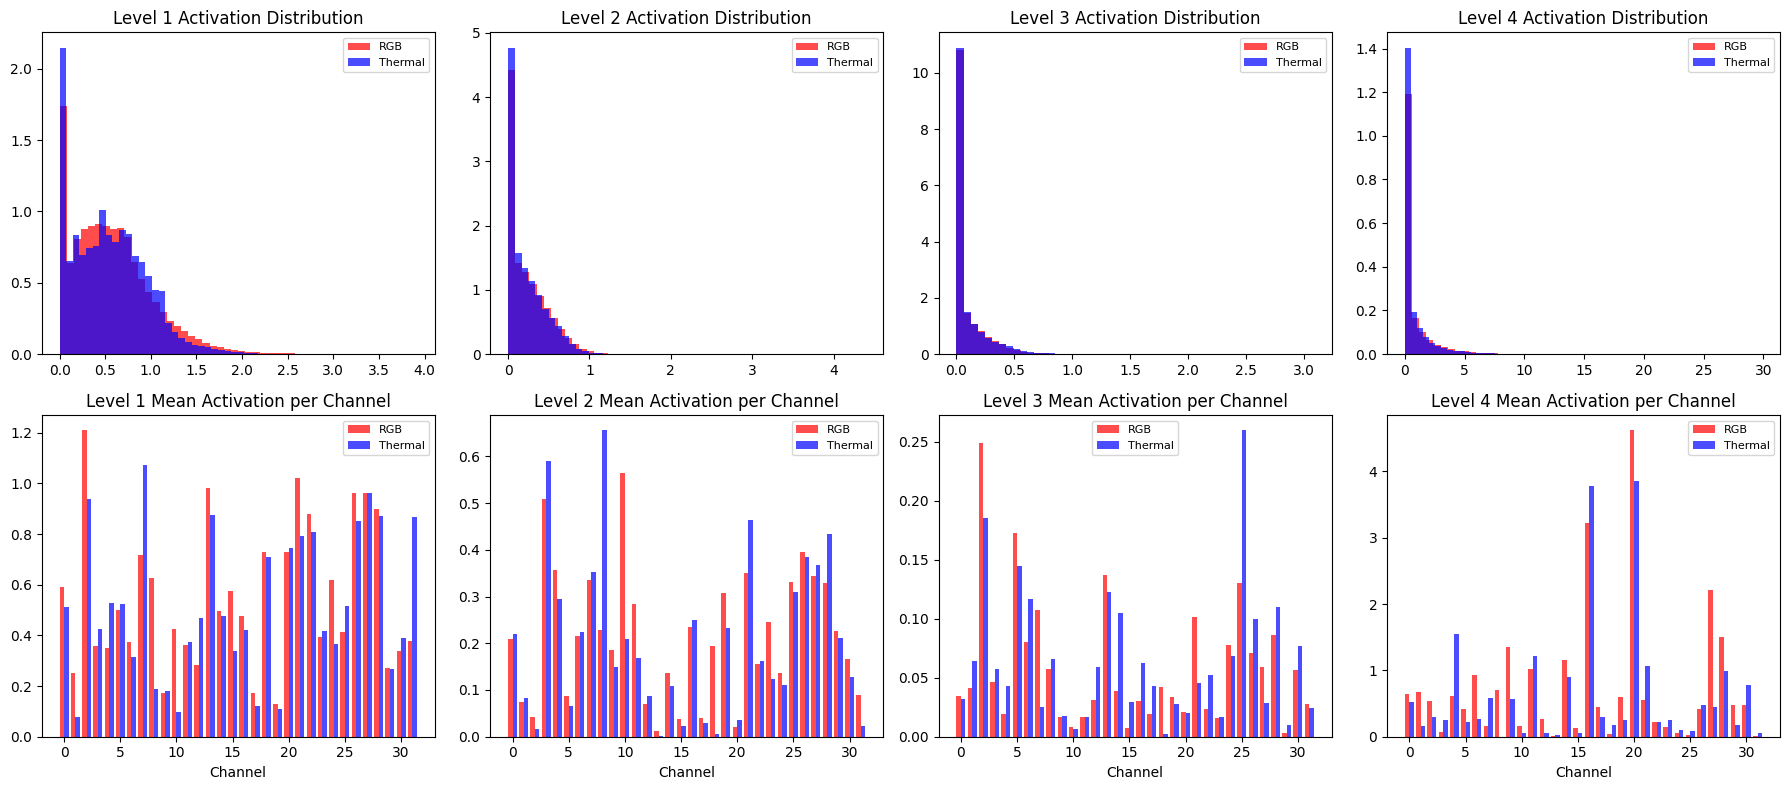

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i in range(4):
    rgb_vals = rgb_features[i][0].cpu().numpy().flatten()
    thermal_vals = thermal_features[i][0].cpu().numpy().flatten()
    
    # Histograms
    axes[0, i].hist(rgb_vals, bins=50, alpha=0.7, color='red', label='RGB', density=True)
    axes[0, i].hist(thermal_vals, bins=50, alpha=0.7, color='blue', label='Thermal', density=True)
    axes[0, i].set_title(f'Level {i+1} Activation Distribution')
    axes[0, i].legend(fontsize=8)
    
    # Mean activation per channel
    rgb_means = rgb_features[i][0].cpu().mean(dim=(1,2)).numpy()
    thermal_means = thermal_features[i][0].cpu().mean(dim=(1,2)).numpy()
    
    x = np.arange(min(32, len(rgb_means)))
    axes[1, i].bar(x - 0.2, rgb_means[:32], 0.4, color='red', alpha=0.7, label='RGB')
    axes[1, i].bar(x + 0.2, thermal_means[:32], 0.4, color='blue', alpha=0.7, label='Thermal')
    axes[1, i].set_title(f'Level {i+1} Mean Activation per Channel')
    axes[1, i].set_xlabel('Channel')
    axes[1, i].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5. Channel-wise Correlation Between Modalities

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\numpy\lib\_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\numpy\lib\_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


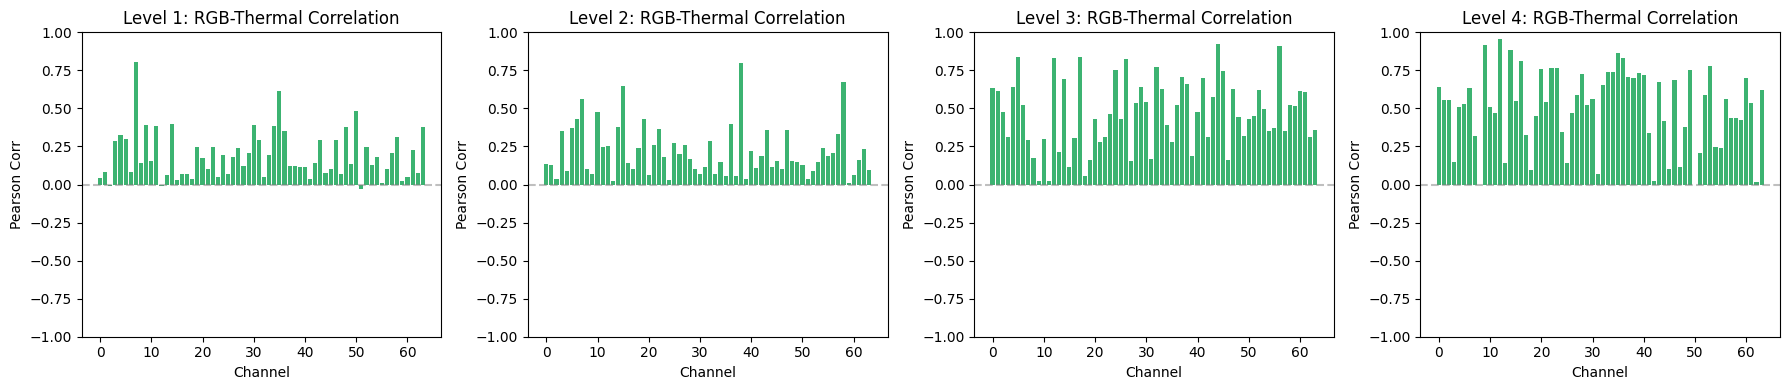

Low correlation = different information = good for fusion!


In [7]:
# Compute correlation between RGB and Thermal features at each level
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for i in range(4):
    rgb_flat = rgb_features[i][0].cpu().numpy().reshape(rgb_features[i].shape[1], -1)
    thermal_flat = thermal_features[i][0].cpu().numpy().reshape(thermal_features[i].shape[1], -1)
    
    # Correlation between corresponding channels
    num_ch = min(rgb_flat.shape[0], 64)
    correlations = []
    for ch in range(num_ch):
        corr = np.corrcoef(rgb_flat[ch], thermal_flat[ch])[0, 1]
        correlations.append(corr if not np.isnan(corr) else 0)
    
    axes[i].bar(range(num_ch), correlations, color='mediumseagreen')
    axes[i].set_title(f'Level {i+1}: RGB-Thermal Correlation')
    axes[i].set_xlabel('Channel')
    axes[i].set_ylabel('Pearson Corr')
    axes[i].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    axes[i].set_ylim(-1, 1)

plt.tight_layout()
plt.show()

print('Low correlation = different information = good for fusion!')